Epoch 1/2
938/938 ━━━━━━━━━━━━━━━━━━━━ 194s 205ms/step - accuracy: 0.8479 - loss: 0.5198 - val_accuracy: 0.9500 - val_loss: 0.1708
Epoch 2/2
938/938 ━━━━━━━━━━━━━━━━━━━━ 200s 214ms/step - accuracy: 0.9376 - loss: 0.2123 - val_accuracy: 0.9647 - val_loss: 0.1195
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.9647 - loss: 0.1195

Test Accuracy: 96.47%


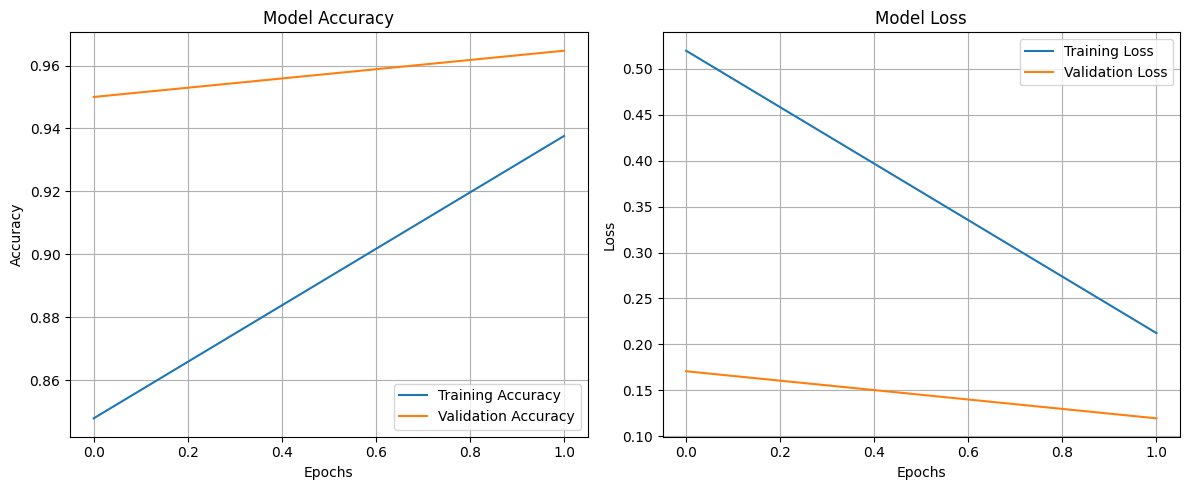

In [2]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.applications import VGG19
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import smart_resize
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

x_train_resized = np.array([
    smart_resize(img, (48, 48)) for img in x_train
])
x_test_resized = np.array([
    smart_resize(img, (48, 48)) for img in x_test
])

x_train_rgb = np.repeat(x_train_resized, 3, axis=-1)
x_test_rgb = np.repeat(x_test_resized, 3, axis=-1)

x_train_rgb = x_train_rgb.astype("float32") / 255.0
x_test_rgb = x_test_rgb.astype("float32") / 255.0

vgg_model = VGG19(
    weights="imagenet",
    include_top=False,
    input_shape=(48, 48, 3)
)

for layer in vgg_model.layers:
    layer.trainable = False

model = models.Sequential([
    vgg_model,
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train_rgb,
    y_train,
    epochs=2,
    batch_size=64,
    validation_data=(x_test_rgb, y_test),
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test_rgb, y_test, verbose=1)

print(f"\nTest Accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
